# 综合实验 1 文本分析 · 任务 1–3：数据装载、缺失值处理与标签编码

- 原始数据：`preprocessed_ratings.csv`（任务 1、2 的产物，4,107,199 行 × 8 列）
- 本 notebook 直接使用该预处理文件，不重复清洗；重点复核数据质量并构造标签（好评/差评）。
- 运行环境：`C:\mlenv` 的 `Python (mlenv)` 内核。

In [1]:
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

SRC = r"D:\DSH-Workspaces\数据科学\综合实验1\src"
sys.path.insert(0, SRC)

from config import RATINGS, RESTAURANTS, TAB, FIG
from data_utils import load_ratings, label_distribution
import viz_utils

viz_utils.set_cn_font()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 任务 1：装载数据集，查看前几行

In [2]:
df_raw = load_ratings(drop_zero=False)      # 读取全量并标记 3.6 伪值，不删任何行
print("数据规模:", df_raw.shape)
print("字段:", list(df_raw.columns))
df_raw.head(10)

数据规模: (4107199, 10)
字段: ['userId', 'restId', 'rating', 'rating_env', 'rating_flavor', 'rating_service', 'timestamp', 'comment', 'is_imputed_rating', 'label']


,userId,restId,rating,rating_env,rating_flavor,rating_service,timestamp,comment,is_imputed_rating,label
0,0,0,3.6,3.0,3.0,2.0,1250584020000,经常去的，不过我自己的卡很久不用，被冻了，只能用爸爸的。吉利莲的巧克力以前选择多些，最近一次...,True,NaN
1,1,0,3.6,4.0,4.0,4.0,1145639040000,"喜欢在这里购物的感觉~~不在市中心,又是凭会员卡购物,因此不会有像家乐福\沃尔马那种人多很挤...",True,NaN
2,3,0,3.6,3.0,4.0,4.0,1162821060000,很适合有车一族来采购，因为没有袋子给的，只有纸箱子！感觉有点像仓库，可是东西好啊，买得多的话...,True,NaN
3,4,0,3.6,3.0,4.0,3.0,1201107000000,里面有一些进口食品还是不错的，但个人感觉商品种类比较少，而且管理不是很灵活，退货比较麻烦。价...,True,NaN
4,5,0,3.6,4.0,4.0,3.0,1218604860000,"虽然是有一些不方便,但购物环境比较舒服,人少,房高,感觉很通透,不像别的商场人多,楼层低,人...",True,NaN
5,6,0,4.0,4.0,4.0,3.0,1281275820000,非常喜欢这个德国超市，他家各类东东都品牌齐全，不像沃尔玛、家乐福之类只有便宜货。经常能找到一...,False,1.0
6,7,0,3.6,3.0,3.0,2.0,1200141900000,感觉像仓储式购物，这才是超市：1 超级大；2 停车超级方便；3品种超级多；4 东西超级正牌超...,True,NaN
7,8,0,4.0,3.0,3.0,3.0,1281945600000,从这家超市刚在湖南开的时候就开始消费，眼看着这里周边由荒凉变得热闹。人生真是好短。\n奇怪的...,False,1.0
8,9,0,3.6,5.0,3.0,2.0,1203575760000,希望自己能系统的评价一下。因为在长沙生活了这么多年，我最喜欢的超市就是麦德龙－－尽管很多人对...,True,NaN
9,10,0,3.6,5.0,5.0,5.0,1222013160000,喜欢在麦德龙购物已经5，6年了。自从麦德龙开了没多久，几个败家妈妈就发现了它，平均一礼拜来一...,True,NaN


In [3]:
df_raw.describe(include="all").T.head(12)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
userId,4107199.0,NaN,NaN,NaN,112008.669884,120043.977683,0.0,21748.0,67844.0,159524.0,542705.0
restId,4107199.0,NaN,NaN,NaN,120833.249798,70377.629925,0.0,60791.0,122763.0,183418.0,243246.0
rating,4107199.0,NaN,NaN,NaN,3.600446,0.735332,0.0,3.0,3.6,4.0,5.0
rating_env,4107199.0,NaN,NaN,NaN,2.724362,0.878504,1.0,2.0,2.7,3.0,5.0
rating_flavor,4107199.0,NaN,NaN,NaN,3.016184,0.90746,1.0,2.0,3.0,4.0,5.0
rating_service,4107199.0,NaN,NaN,NaN,2.699684,0.884101,1.0,2.0,2.7,3.0,5.0
timestamp,4107199.0,NaN,NaN,NaN,1275829772111.490967,43330396442.457047,1049731200000.0,1250583540000.0,1288878840000.0,1309968300000.0,1328681040000.0
comment,4107199,4104260,感叹一下，\n现在连卖面包的都能上市啊，\n真是太厉害了~！\n不过85度C的出现的确对这个...,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_imputed_rating,4107199,2,False,2979629,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,2979614.0,NaN,NaN,NaN,0.229671,0.934397,-1.0,-1.0,1.0,1.0,1.0


## 任务 2：缺失值检查与复核

说明：任务 1、2 已在上一步 notebook 中完成清洗与导出，本实验直接复用。这里复核两件事：

1. 导出文件中各列是否仍有缺失；
2. 任务 2 用**全局均值 3.6** 填充了缺失的 `rating`——真实评分只取整数，因此 `rating == 3.6` 是伪值，共 1,127,570 行（27.45%），后续监督任务必须剔除。

In [4]:
print("各列缺失值：")
print(df_raw.isnull().sum())
print()
print("rating==3.6（均值填充伪值）行数:", int(df_raw["is_imputed_rating"].sum()),
      "占比: %.2f%%" % (100 * df_raw["is_imputed_rating"].mean()))
print("rating==0（异常值，15 条）行数:", int((df_raw["rating"] == 0.0).sum()))
print("评论长度: 均值 %.1f | 最短 %d | 最长 %d" % (
      df_raw["comment"].str.len().mean(), df_raw["comment"].str.len().min(),
      df_raw["comment"].str.len().max()))

# 删除 15 条 0 分异常，得到后续统一使用的数据
df = df_raw[df_raw["rating"] != 0.0].copy()
print("删除 0 分后:", df.shape)

各列缺失值：


userId                     0
restId                     0
rating                     0
rating_env                 0
rating_flavor              0
rating_service             0
timestamp                  0
comment                    0
is_imputed_rating          0
label                1127585
dtype: int64

rating==3.6（均值填充伪值）行数: 1127570 占比: 27.45%
rating==0（异常值，15 条）行数: 15


评论长度: 均值 144.7 | 最短 10 | 最长 2001


删除 0 分后: (4107184, 10)


In [5]:
# 按年看评分可用性：证明 2009 年以前基本没有有效星级
df["year"] = pd.to_datetime(df["timestamp"], unit="ms").dt.year
tbl = pd.DataFrame({
    "评论数": df.groupby("year").size(),
    "有效评分(1-5星)": df[df["rating"].isin([1,2,3,4,5])].groupby("year").size(),
    "3.6伪值": df[df["is_imputed_rating"]].groupby("year").size(),
}).fillna(0).astype(int)
tbl["有效评分占比"] = (tbl["有效评分(1-5星)"] / tbl["评论数"] * 100).round(1)
tbl

,评论数,有效评分(1-5星),3.6伪值,有效评分占比
year,,,,
2003,246,0,246,0.0
2004,2587,0,2587,0.0
2005,32315,0,32315,0.0
2006,73409,0,73409,0.0
2007,132715,0,132715,0.0
2008,460809,0,460809,0.0
2009,655441,230574,424867,35.2
2010,892223,891959,264,100.0
2011,1688652,1688359,293,100.0


## 任务 3：5 级评论编码为好评(1) / 差评(0)

约定（见方案 §3）：

- **口径 A（主实验）**：4–5 星 → 1，1–2 星 → 0，3 星（中性）与 3.6（伪值）剔除；
- **口径 B（对照实验）**：4–5 星 → 1，1–3 星 → 0；3.6 剔除。
- 全站极化样本（好评+差评）好评率 = 88.62%。

In [6]:
dist = label_distribution(df)          # 评分分布表（含伪值、异常值）
dist

,rating,count,share,label
0,1.0,80966,1.97,0（差评）
1,2.0,139981,3.41,0（差评）
2,3.0,1037168,25.25,-1（中性）
3,3.6,1127570,27.45,NaN（缺失填充）
4,4.0,1351432,32.90,1（好评）
5,5.0,370067,9.01,1（好评）


In [7]:
import importlib, data_utils
importlib.reload(data_utils)
from data_utils import encode_label

label_a = encode_label(df["rating"], "A")
label_b = encode_label(df["rating"], "B")
n = len(df)
print("口径 A：好评 %d (%.2f%%) | 差评 %d (%.2f%%) | 中性 %d (%.2f%%) | 无标签 %d (%.2f%%)" % (
    (label_a == 1).sum(), 100*(label_a == 1).mean(),
    (label_a == 0).sum(), 100*(label_a == 0).mean(),
    (label_a == -1).sum(), 100*(label_a == -1).mean(),
    np.isnan(label_a).sum(), 100*np.isnan(label_a).mean()))
print("口径 B：好评 %d | 差评 %d | 无标签 %d" % (
    (label_b == 1).sum(), (label_b == 0).sum(), np.isnan(label_b).sum()))
print("极化样本好评率: %.2f%%" % (100 * (label_a == 1).sum() / ((label_a == 1).sum() + (label_a == 0).sum())))

口径 A：好评 1721499 (41.91%) | 差评 220947 (5.38%) | 中性 1037168 (25.25%) | 无标签 1127570 (27.45%)
口径 B：好评 1721499 | 差评 1258115 | 无标签 1127570
极化样本好评率: 88.63%


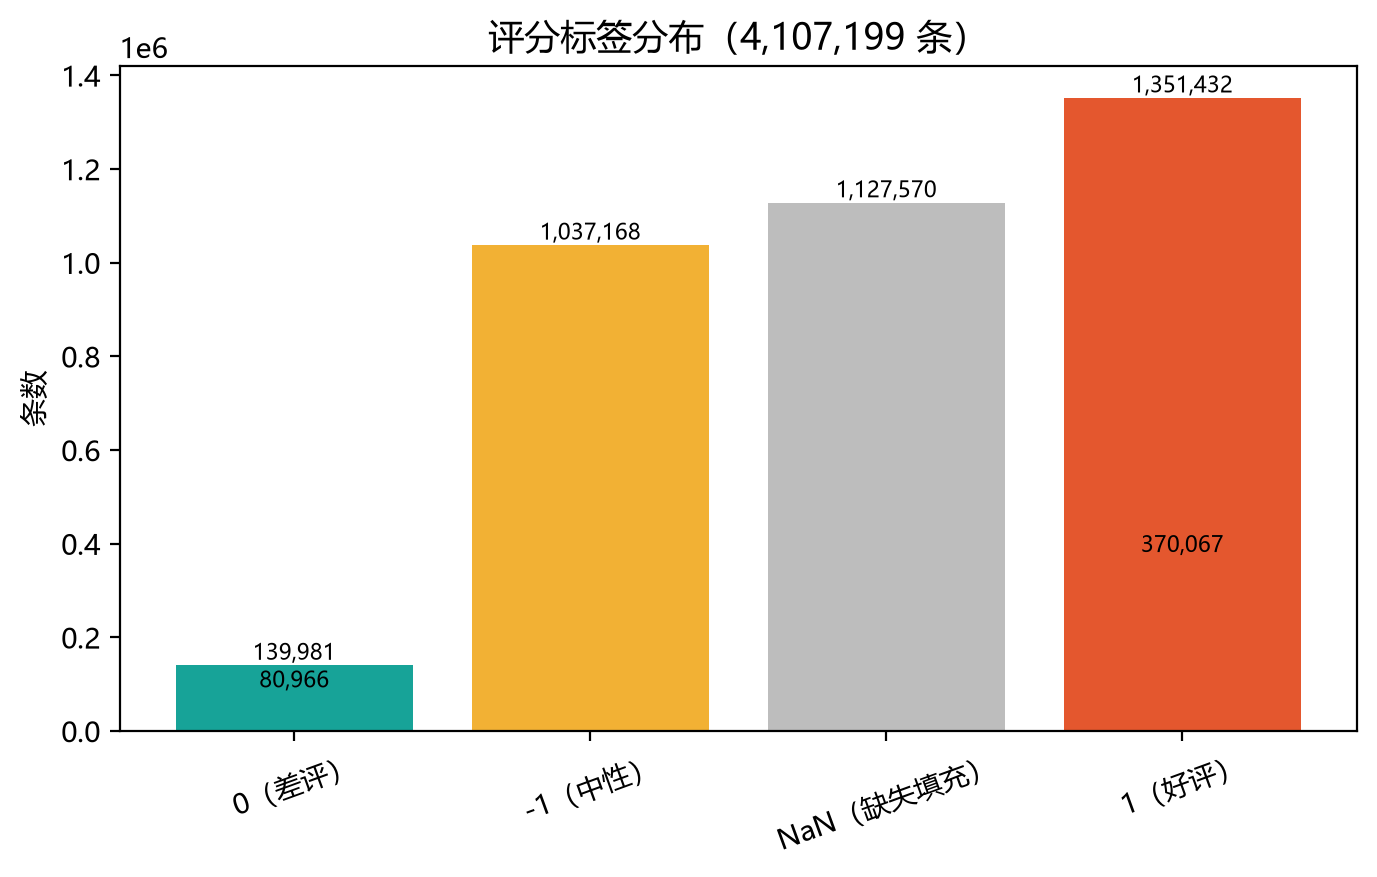

saved: D:\DSH-Workspaces\数据科学\综合实验1\output\tables\label_dist.csv


In [8]:
fig = viz_utils.plot_label_distribution(
    dist.set_index("label")["count"], "fig01_label_distribution.png")
display(Image(filename=str(fig)))

dist.to_csv(TAB / "label_dist.csv", index=False, encoding="utf-8-sig")
print("saved:", TAB / "label_dist.csv")

## 小结

- 数据规模 4,107,199 行；3.6 伪值 1,127,570 行（27.45%），2009 年以前几乎无有效评分；
- 口径 A：好评 1,721,499、差评 220,947（剔除 15 条 0 分后）、中性 1,037,168、无标签 1,127,570；
- 极化样本好评率 88.62%，类别不均衡（约 7.8 : 1），后续需报告 macro-F1 与逐类指标。